# Team T085 · Section E · Project 26
Phase 1: Machine Learning

The expanded run reuses the previously inspected test partition. Training-only selection and validation-only robustness are preserved; this is not a fresh independent holdout.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
assert (ROOT/'src').exists(), 'Start Jupyter in the project folder.'
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
TABLES=ROOT/'results/tables'
FIGURES=ROOT/'results/figures'
def table(name): return pd.read_csv(TABLES/name)
def figure(name): display(Image(filename=str(FIGURES/name)))


## Assembled Phase 1 narrative
Owner: Anshvardhan integrates reviewed contributions from all roles. This notebook summarizes the completed classical pipeline and links its frozen interfaces to Phase 2.

In [2]:
display(Markdown((ROOT/'README.md').read_text()))

# Card Fraud Triage: GMM Density Scoring vs Autoencoder Anomaly Detector

**Team T085 · Section E · Project 26 · Phase 1: Machine Learning**

The project learns legitimate transaction behavior and ranks later mixed transactions for a limited fraud review queue. Phase 1 includes GMM density scoring, classical comparators, numerical sensitivity studies and descriptive error analysis. Autoencoder training and hybrid evaluation are Phase 2.

## Reproduce

```bash
python3 -m venv .venv
source .venv/bin/activate
pip install -r requirements.txt
# Download the original ULB/Kaggle creditcard.csv into data/raw/
python run_all.py
python -m unittest discover -s tests -v
jupyter lab
```

Dataset: [ULB/Kaggle Credit Card Fraud Detection](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud). Original CSV: 284,807 rows, 492 frauds, no missing values. The CSV and fitted joblib models are excluded from Git. `results/models/README.md` documents regeneration. An external CSV path works with `python run_all.py --data /absolute/path/creditcard.csv`.

The default command executes the full project. `--skip-robustness` is only a quick rerun. Saved split indices are reused and checked against the dataset checksum, configured fractions, chronology and legitimate training membership. Mismatches fail instead of silently changing the experiment.

## Team responsibilities

| Role | Member | Responsibility |
|---|---|---|
| 1 | Gauri mishra | Data, training EDA and saved chronological splits |
| 2 | Farhana Pervin | Preprocessing, feature decisions and PCA |
| 3 | Aaditya Yadav | GMM selection and integration |
| 4 | Bhumi Rastogi | Metrics, threshold calibration and review capacity |
| 5 | Anshvardhan Badkur | Robustness, error analysis and final narrative |

Assignments are ownership and review responsibilities. Actual personal contributions require real commit/review evidence in `CONTRIBUTIONS.md`.

## Repository structure

```text
configs/                 Fixed experiment configuration and team metadata
src/                     Data, preprocessing, GMM, baselines, metrics, robustness, error analysis
tests/                   Fourteen protocol and behavior checks
notebooks/               Seven executed notebooks, including an assembled Phase 1 summary
data/processed/          Frozen split indices, dataset checksum and split manifest
results/figures/         EDA, model selection, validation/test PR, sensitivity and error plots
results/tables/          Selection, triage, robustness, workload and error-analysis results
results/scores/          Row-aligned validation/test score arrays
results/models/          Model regeneration guide; fitted binaries remain local
docs/                    Protocols, data card, audit, editable presentation and PDF
reports/                 Literature, robustness, error analysis and compiled IEEE report
reports/ieee_report/     Compilable IEEEtran source and referenced figures
scripts/                 Narrative/table synchronization and report rebuilding
guides/                  Phase 1 checklist and viva preparation
run_all.py               Complete reproducible experiment
```

## Experimental protocol

- Approximate chronological 60/20/20 partitions, preserving equal timestamps. There are 170,528 legitimate training records, 57 validation frauds and 75 test frauds.
- Explicit `data/processed/split_indices.npz` fixes membership for every model and Phase 2. Provider-created PCA features cannot be independently refit.
- Inputs are V1-V28 and log1p(Amount). Time defines the split and EDA. Preprocessing fits on legitimate training only.
- Structural search crosses K={1,2,4,8,12,16,20} and four covariance types. Predetermined one-factor trials vary regularization, initialization count and iteration limit on the structural winner. Minimum converged training BIC chooses the final GMM. AIC is reported separately.
- The same training rows feed PCA reconstruction, Isolation Forest and an explicitly approximate RBF one-class SVM. Baseline settings stay fixed.
- Validation calibrates strict score>threshold policies at FPR budgets 0.1%, 0.5%, 1% and 5%. Capacity policies review the top 0.1%, 0.5%, 1% or top 100 scores, with stable chronological tie breaking.
- Robustness uses validation only: dimensions 5/10/20/29, all four covariance types, three seeds and nested 10%/50%/100% training subsets at fixed K=4. Raw AIC/BIC are not compared across dimensional spaces or different fitting populations.
- Post-freeze error analysis describes missed frauds, top false positives and review workload. It does not retune the model.

**Test reuse disclosure:** this is an expanded follow-up to the original Phase 1 run. The same test partition was already inspected. Model selection still uses training BIC, robustness uses validation, and thresholds freeze before the current test computation, but these results are not a fresh independent holdout. The initial run is preserved in Git history at commit `753087b`.

## Recorded results

Training BIC selected **20 full-covariance components**, reg_covar=1e-06, n_init=2 and max_iter=300. 33 primary fits and 26 robustness fits are recorded. The selected covariance condition number is approximately 17,759,113.

| Model | Test AP | Trapezoidal PR AUC |
|---|---:|---:|
| gmm | 0.5822 | 0.5787 |
| isolation_forest | 0.0538 | 0.0524 |
| pca | 0.1573 | 0.1540 |
| approx_ocsvm | 0.0014 | 0.0014 |

GMM AP's descriptive 95% stratified bootstrap interval is 0.4634-0.7123. At the **0.5% validation FPR budget**, GMM catches **57/75 frauds**, with **175 false positives**, **0.308% actual test FPR**, and **24.57% precision** across **232 alerts**.

The separate top-0.5% capacity policy reviews 284 records and catches 57 frauds, precision 20.07% and recall 76.00%. Top 100 captures 56 frauds. The difference reflects different review policies.

## Deliverables

- `reports/T085_Phase1_IEEE_Report.pdf` and `reports/ieee_report/main.tex`
- `docs/T085_Phase1.pptx` and `docs/T085_Phase1.pdf`
- `reports/literature_review.md`, `reports/robustness_analysis.md`, `reports/error_analysis.md`
- Seven executed notebooks, the frozen split file and versioned numerical outputs
- `guides/VIVA_GUIDE.md`, `guides/PHASE1_ONLY.md`, `docs/FINAL_AUDIT.md`

## Regenerate the report

```bash
python scripts/update_deliverables.py
python scripts/build_report.py
tectonic reports/ieee_report/main.tex
```

Copy the compiled `main.pdf` to `reports/T085_Phase1_IEEE_Report.pdf` for submission. `scripts/build_presentation.mjs` recreates the editable deck with the bundled Artifact Tool runtime described in its header. Presentation charts also remain manually editable. Re-run and inspect all exported artifacts after changing results.

## Limitations

Only two historical days and 75 test frauds limit generalization. Exact duplicates are retained because transaction IDs are absent. AIC/BIC optimize density fit, not fraud recall. This is a bounded staged search, not a global optimum. Robustness studies use fixed K=4 and evaluate validation quality; they are not a comprehensive architecture search. Continuous density is not a fraud posterior. AP intervals condition on observed class counts and omit temporal dependence and refitting uncertainty. Test reuse must be disclosed in Phase 2.

Scope follows the faculty [Phase 1 instructions](https://docs.google.com/document/d/1ZBr-3LoIEFzXz1pxziGqxSVewOAI3sacAzXRaHxtF_Q/edit). Literature citations are in the report and literature review.


In [3]:
display(table('split_summary.csv').drop(columns='index_sha256'))
display(table('gmm_grid.csv').query('selected'))
display(table('ranking_metrics.csv').query("split=='test'"))
display(table('seed_summary.csv'))

,split,rows,fraud,legitimate,base_rate,time_min,time_max
0,train,170888,360,170528,0.002107,0.0,120396.0
1,validation,56958,57,56901,0.001001,120397.0,145248.0
2,test,56961,75,56886,0.001317,145249.0,172792.0


,components,covariance,reg_covar,n_init,max_iter,seed,fit_rows,dimensions,aic,bic,...,iterations,min_weight,min_cov_eigenvalue,max_cov_condition,ill_conditioned,error,warnings,seconds,stage,selected
28,20,full,0.000001,2,300,26,170528,29,-1.333943e+07,-1.324600e+07,...,63,0.001939,1.000000e-06,1.775911e+07,True,NaN,NaN,44.880785,optimizer,True


,model,split,average_precision,pr_auc_trapezoidal,roc_auc,base_rate,ap_ci_lower,ap_ci_upper
1,gmm,test,0.582203,0.578669,0.918662,0.001317,0.463446,0.712348
3,isolation_forest,test,0.053800,0.052400,0.951951,0.001317,0.039910,0.071807
5,pca,test,0.157348,0.154011,0.964220,0.001317,0.121233,0.207970
7,approx_ocsvm,test,0.001431,0.001409,0.541137,0.001317,0.001305,0.001602


,covariance,runs,converged_runs,validation_ap_mean,validation_ap_std,validation_ap_min,validation_ap_max,maximum_condition
0,diag,3,3,0.058939,0.000238,0.058704,0.059181,353.241082
1,full,3,3,0.353450,0.248788,0.066400,0.506859,332244.916084
2,spherical,3,3,0.029829,0.001643,0.027946,0.030968,1.000000
3,tied,3,3,0.107469,0.058080,0.073570,0.174533,51095.541071


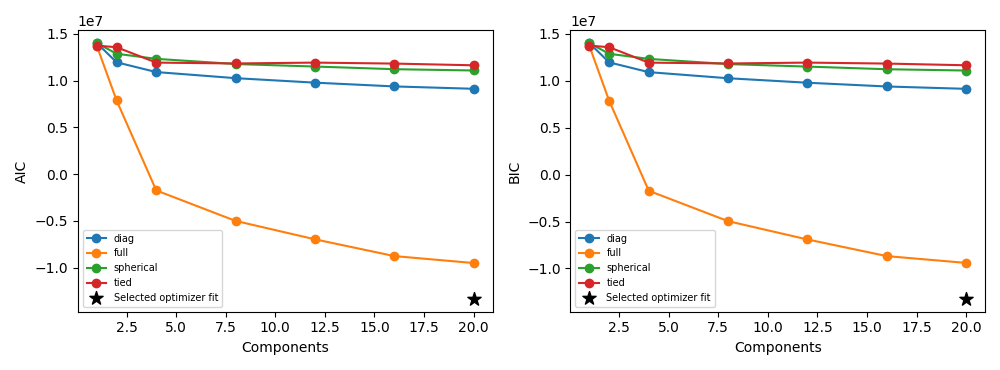

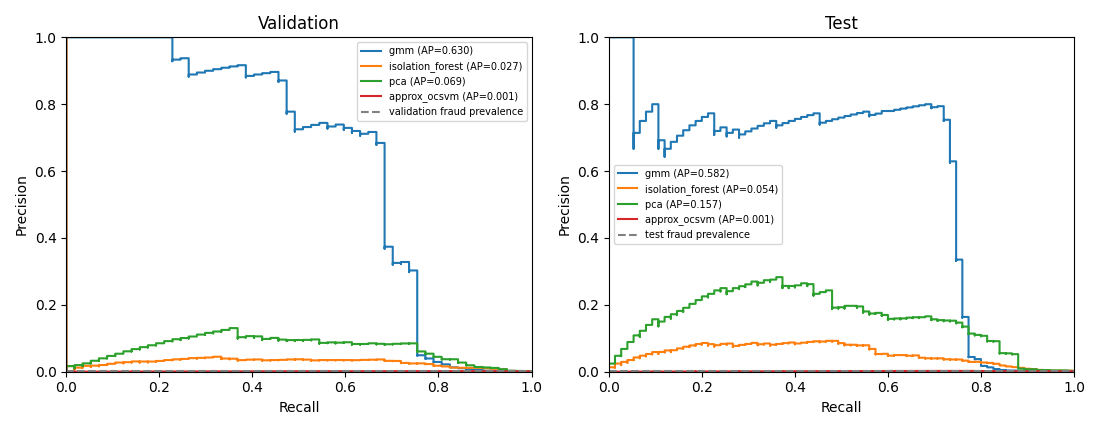

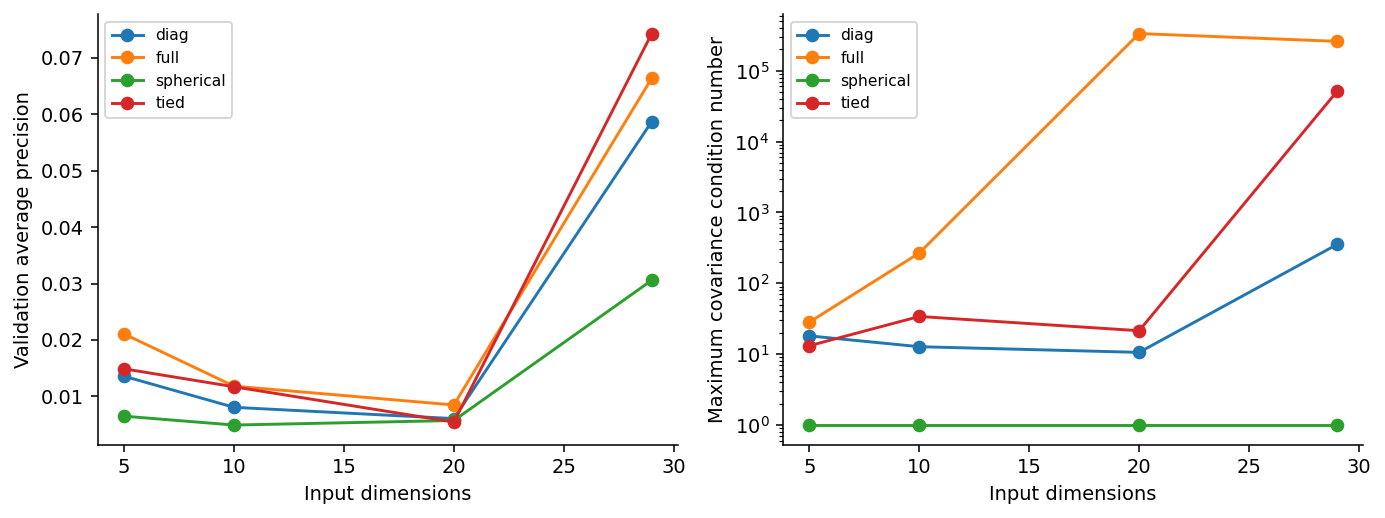

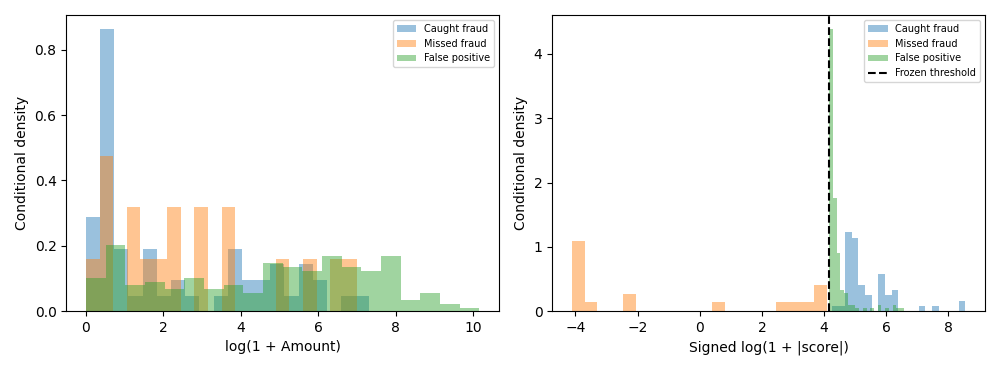

In [4]:
figure('gmm_selection.png')
figure('pr_curves.png')
figure('dimensionality_stability.png')
figure('error_analysis.png')

## Phase 2 placeholder
Train an undercomplete or denoising autoencoder only on the saved legitimate training rows. Reuse the exact full preprocessing pipeline and model-independent evaluation harness. Use validation for architecture, early stopping and thresholds. Disclose the already inspected test partition. A hybrid requires a rationale and ablation evidence; no neural or hybrid training is claimed in Phase 1.